In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import umap
import seaborn as sns

I0000 00:00:1795536451.296506  562101 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795536451.297056  562101 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795536451.341480  562101 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795536452.554070  562101 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [2]:
# Change for your data
root_path = Path("/data/smfish/20260413_bartelle_smFISH_control")

In [3]:
root_path_cryo = Path("/data/smfish/20260311_bartelle_smFISH_cryo_48hr_male")


In [4]:
output_dir = root_path / "big_fish" / "results" / "all_tiles_2D"
matrix_path = output_dir / "filtered_counts.csv"

counts = pd.read_csv(matrix_path)

In [5]:
output_dir_cryo = root_path_cryo / "big_fish" / "results" / "all_tiles_2D"
matrix_path_cryo = output_dir_cryo / "filtered_counts.csv"
counts_cryo = pd.read_csv(matrix_path_cryo)

In [6]:
counts_cryo

,Angpt1,Crmp1,Dcx,Hdac11,Itgam,Notch2,Ptch1,Serpine1,Shh,Slc1a3,Tcf12,Tek,Tgfb1,Tgfbi,Aif1,Nnat
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,9.0,0.0,0.0,0.0,0.0,0.0,3.0
3,0.0,35.0,1.0,15.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,2.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9606,0.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0
9607,0.0,32.0,2.0,3.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
9608,0.0,23.0,1.0,4.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
9609,0.0,4.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Elbow Plots

In [7]:
# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

In [8]:
# Define marker genes for the cell type
marker_genes_uglia = ["Aif1", "Itgam"]

# Define marker genes for the cell type
marker_genes_np = ["Dcx", "Nnat"]

# Define marker genes for the cell type
marker_gene_ast = ["Slc1a3"]

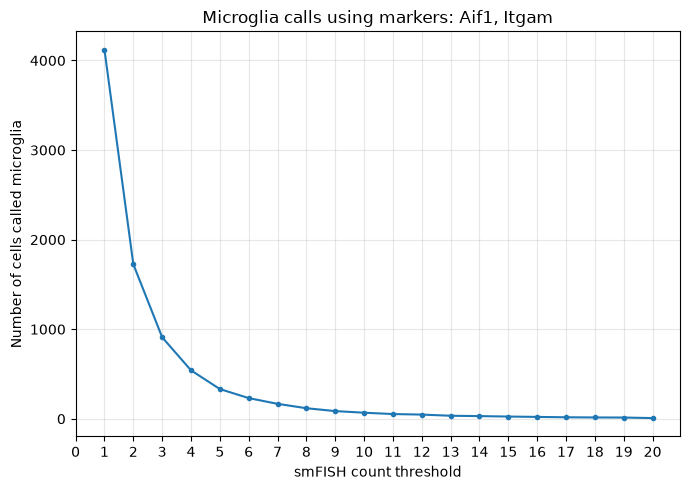

In [9]:
# SUM

# A cell is positive when the sum of all marker counts reaches the threshold
# Aif1 + Itgam >= threshold
microglia_counts = [
    (counts[marker_genes_uglia].sum(axis=1) >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, microglia_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called microglia")
plt.title(f"Microglia calls using markers: {', '.join(marker_genes_uglia)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

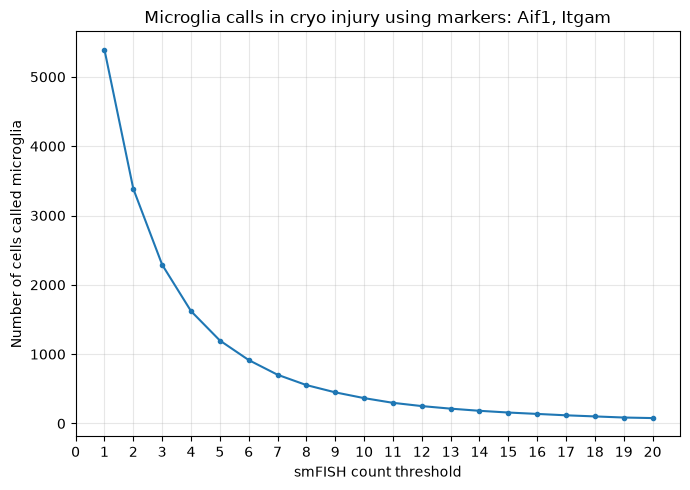

In [10]:
# A cell is positive when the sum of all marker counts reaches the threshold
# Aif1 + Itgam >= threshold
microglia_counts_cryo = [
    (counts_cryo[marker_genes_uglia].sum(axis=1) >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, microglia_counts_cryo, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called microglia")
plt.title(f"Microglia calls in cryo injury using markers: {', '.join(marker_genes_uglia)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

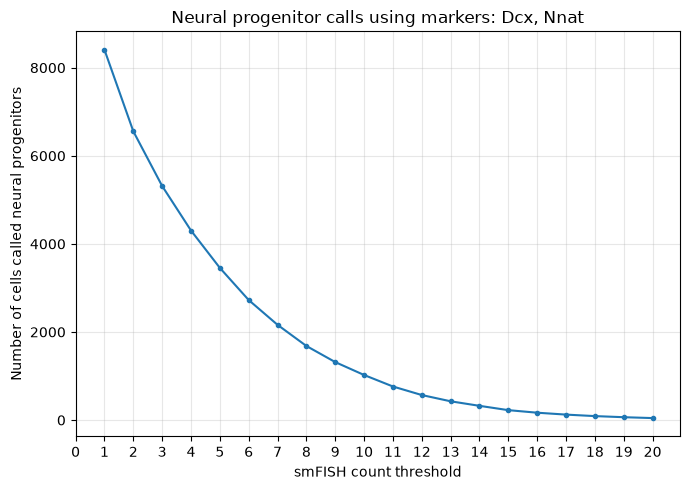

In [11]:
# A cell is positive when the sum of all marker counts reaches the threshold
np_counts = [
    (counts[marker_genes_np].sum(axis=1) >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, np_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called neural progenitors")
plt.title(f"Neural progenitor calls using markers: {', '.join(marker_genes_np)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

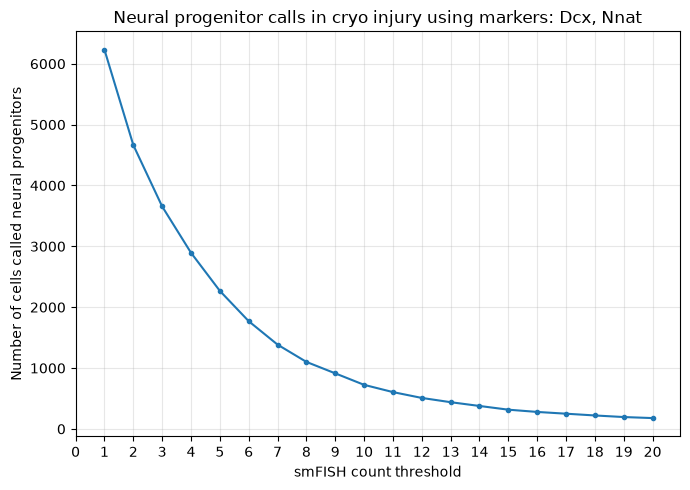

In [12]:
# A cell is positive when the sum of all marker counts reaches the threshold
np_counts_cryo = [
    (counts_cryo[marker_genes_np].sum(axis=1) >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, np_counts_cryo, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called neural progenitors")
plt.title(f"Neural progenitor calls in cryo injury using markers: {', '.join(marker_genes_np)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

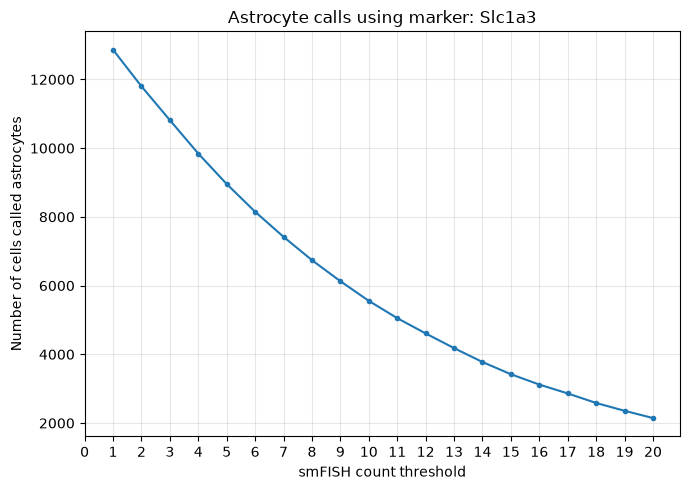

In [13]:
astrocyte_counts = [
    (counts[marker_gene_ast] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, astrocyte_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called astrocytes")
plt.title(f"Astrocyte calls using marker: {', '.join(marker_gene_ast)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

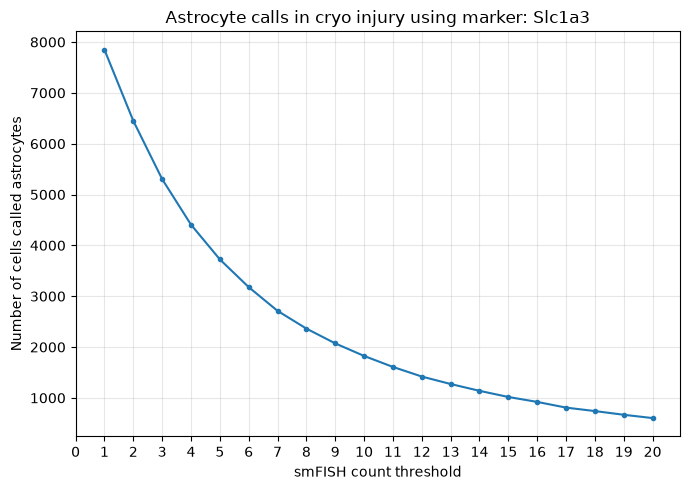

In [14]:
astrocyte_counts_cryo = [
    (counts_cryo[marker_gene_ast] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, astrocyte_counts_cryo, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called astrocytes")
plt.title(f"Astrocyte calls in cryo injury using marker: {', '.join(marker_gene_ast)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Thresholds

In [26]:
uglia_threshold = 2

np_threshold = 7

ast_threshold = 8

uglia_threshold_cryo = 4

np_threshold_cryo = 7

ast_threshold_cryo = 4

In [23]:
marker_genes_dict = {
    "Aif1": "microglia",
    "Itgam": "microglia",
    "Slc1a3": "astrocyte",
    "Dcx": "neural progenitor",
    "Nnat": "neural progenitor",
}

# Marker genes used by the classification rules
required_genes = list(marker_genes_dict)

marker_counts = counts[required_genes].astype(float)

In [27]:
# A cell is positive when the sum of all marker counts reaches the threshold
# Aif1 + Itgam >= threshold
is_microglia = (marker_counts["Aif1"] + marker_counts["Itgam"]) >= uglia_threshold

# is_np = (marker_counts["Dcx"] + marker_counts["Nnat"]) >= np_threshold

is_ast = (marker_counts["Slc1a3"]) >= ast_threshold

# Assign labels
cell_type = pd.Series("unclassified", index=counts.index)

cell_type.loc[is_microglia] = "microglia"
cell_type.loc[is_ast] = "astrocyte"
# cell_type.loc[is_np] = "neural_progenitor"


cell_type.value_counts()

astrocyte       6740
unclassified    6450
microglia        498
Name: count, dtype: int64

In [28]:
# Count how many categories each cell meets
category_matrix = pd.DataFrame(
    {
        "microglia": is_microglia,
        "astrocyte": is_ast,
        # "neural_progenitor": is_np,
    },
    index=counts.index,
)

n_categories = category_matrix.sum(axis=1)
single_label = category_matrix.idxmax(axis=1)

# 1. Exclude cells meeting thresholds for multiple categories
cell_labels_multilabel_excluded = single_label.where(
    n_categories == 1, "unclassified"
)

# 2. Assign overlapping cells based on normalized marker counts.
# Two-marker categories use their mean count; astrocytes have one marker.
category_scores = pd.DataFrame(
    {
        "microglia": (
            marker_counts["Aif1"] + marker_counts["Itgam"]
        ) / 2,
        "astrocyte": marker_counts["Slc1a3"],
        "neural_progenitor": (
            marker_counts["Dcx"] + marker_counts["Nnat"]
        ) / 2,
    },
    index=counts.index,
)

highest_score = category_scores.max(axis=1)
n_highest = category_scores.eq(highest_score, axis=0).sum(axis=1)

cell_labels_higher = pd.Series("unclassified", index=counts.index)
cell_labels_higher.loc[n_categories > 0] = single_label.loc[n_categories > 0]
cell_labels_higher.loc[
    (n_categories > 1) & (n_highest == 1)
] = category_scores.idxmax(axis=1).loc[
    (n_categories > 1) & (n_highest == 1)
]

# 3. Assign "multilabel" to cells meeting multiple category thresholds
cell_labels = pd.Series("unclassified", index=counts.index)
cell_labels.loc[n_categories == 1] = single_label.loc[n_categories == 1]
cell_labels.loc[n_categories > 1] = "multilabel"

# Print label counts
print("cell_labels_multilabel_excluded:")
print(cell_labels_multilabel_excluded.value_counts())

print("\ncell_labels_higher:")
print(cell_labels_higher.value_counts())

print("\ncell_labels:")
print(cell_labels.value_counts())

cell_labels_multilabel_excluded:
unclassified    7678
astrocyte       5512
microglia        498
Name: count, dtype: int64

cell_labels_higher:
astrocyte            6737
unclassified         6450
microglia             500
neural_progenitor       1
Name: count, dtype: int64

cell_labels:
unclassified    6450
astrocyte       5512
multilabel      1228
microglia        498
Name: count, dtype: int64


In [34]:
# Classify cryo cells using cryo-specific thresholds
cryo_classification_markers = counts_cryo[required_genes].astype(float)

cryo_is_microglia = (
    cryo_classification_markers["Aif1"]
    + cryo_classification_markers["Itgam"]
) >= uglia_threshold_cryo

cryo_is_astrocyte = (
    cryo_classification_markers["Slc1a3"] >= ast_threshold_cryo
)

cryo_category_matrix = pd.DataFrame(
    {
        "microglia": cryo_is_microglia,
        "astrocyte": cryo_is_astrocyte,
    },
    index=counts_cryo.index,
)

cryo_n_categories = cryo_category_matrix.sum(axis=1)
cryo_single_label = cryo_category_matrix.idxmax(axis=1)

cryo_cell_labels = pd.Series(
    "unclassified",
    index=counts_cryo.index,
)
cryo_cell_labels.loc[cryo_n_categories == 1] = (
    cryo_single_label.loc[cryo_n_categories == 1]
)
cryo_cell_labels.loc[cryo_n_categories > 1] = "multilabel"

cryo_cell_labels.value_counts()

unclassified    4617
astrocyte       3373
multilabel      1034
microglia        587
Name: count, dtype: int64

## Violin plot

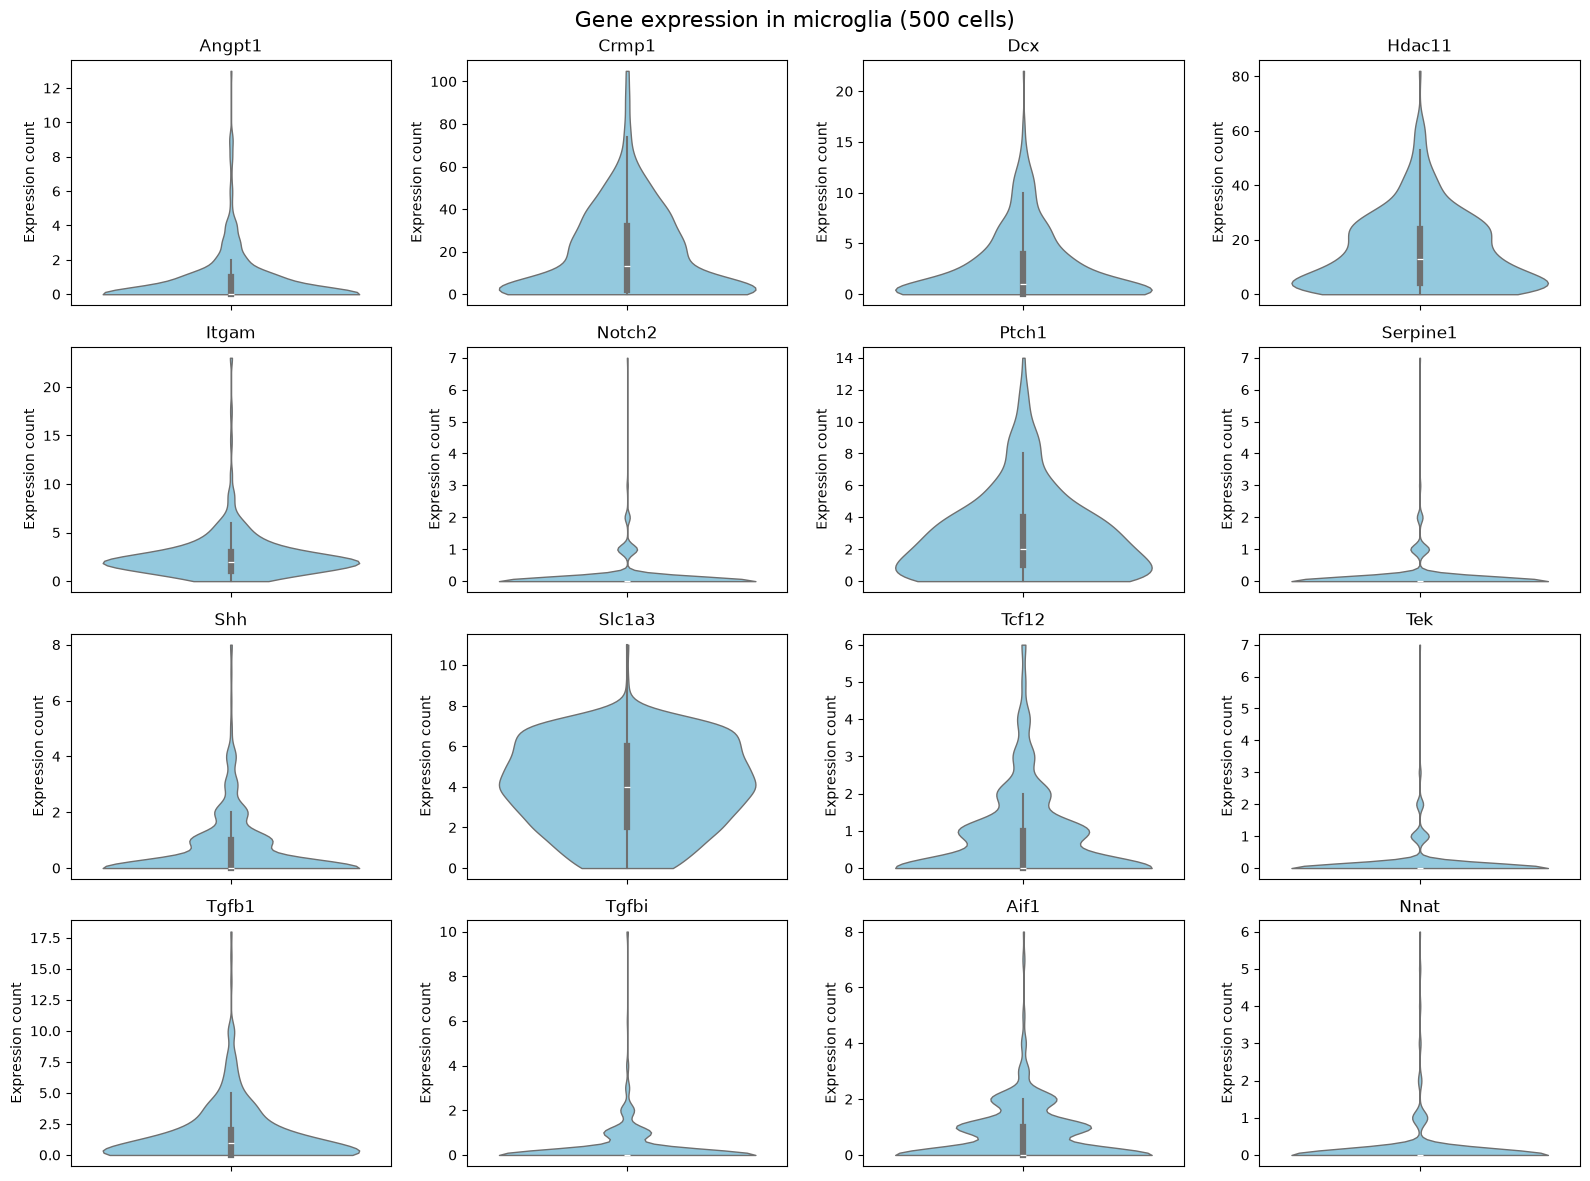

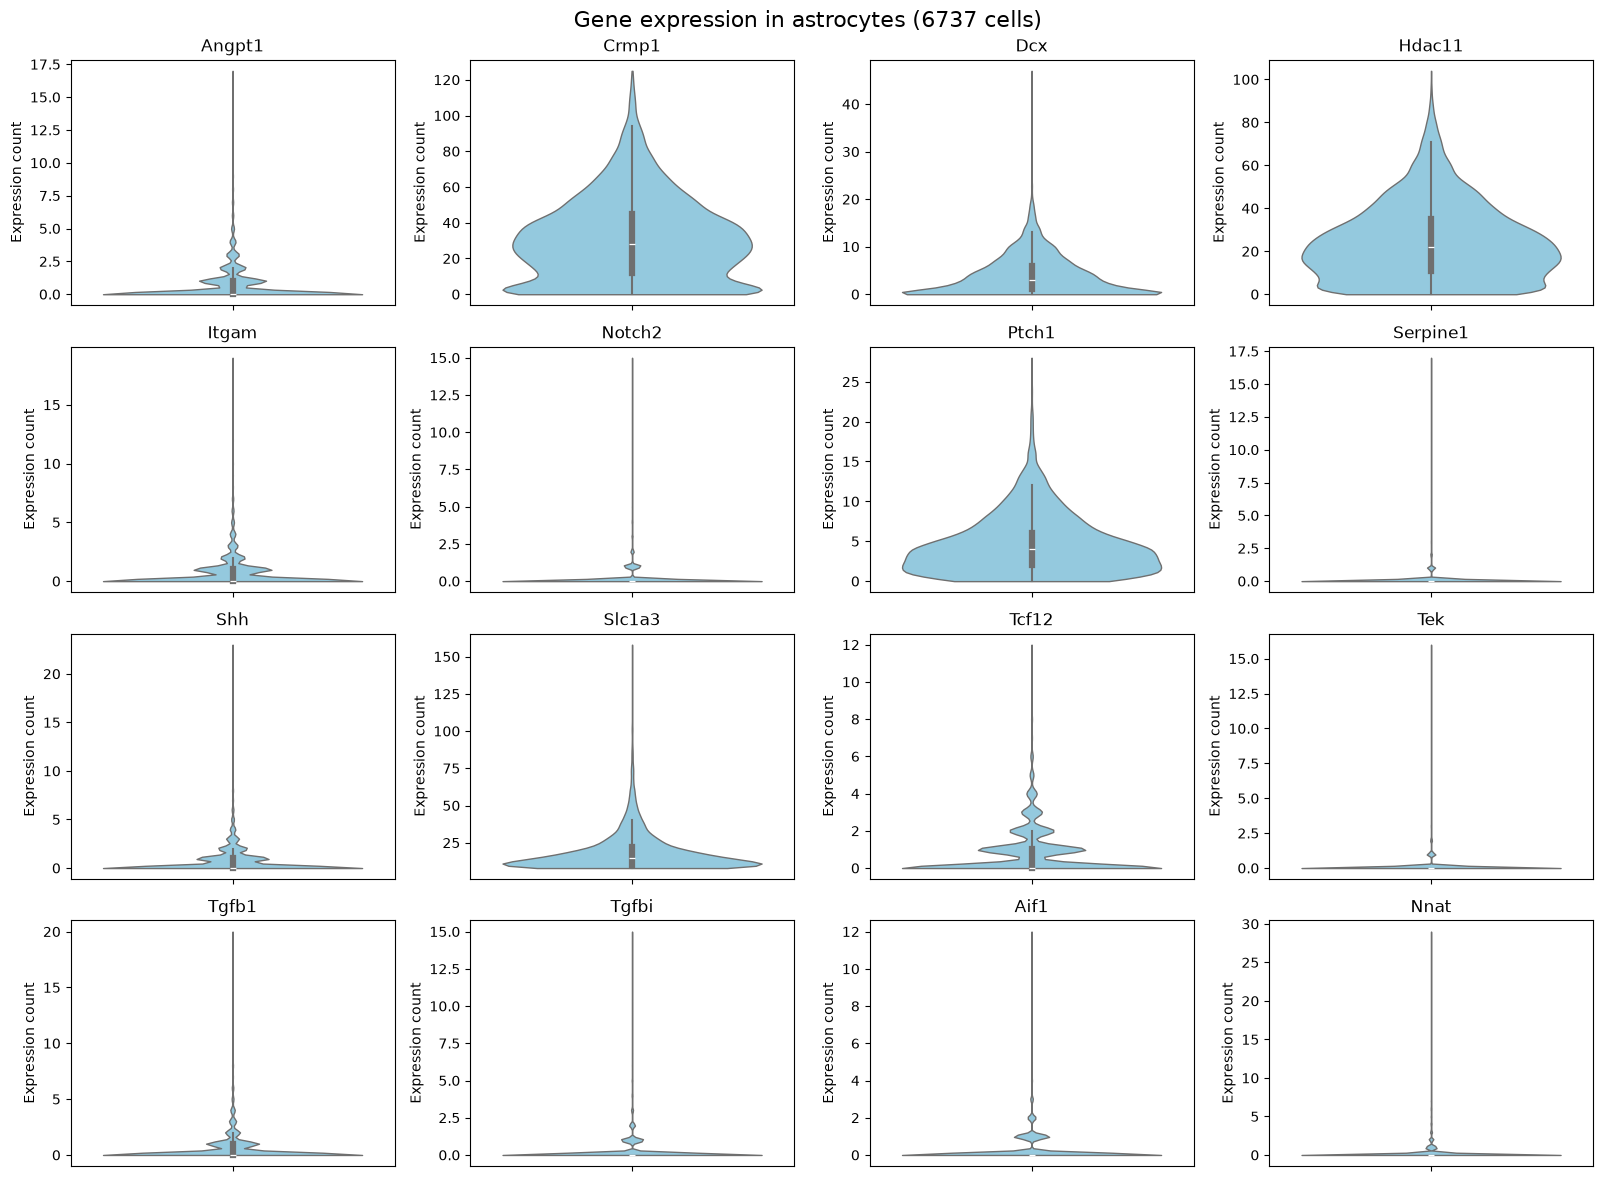

In [29]:
def plot_gene_violin(expression_counts, label_mask, title):
    genes = expression_counts.columns
    plot_data = expression_counts.loc[label_mask, genes].copy()
    
    if plot_data.empty:
        print(f"No cells found for {title}")
        return

    fig, axes = plt.subplots(4, 4, figsize=(16, 12), sharey=False)
    axes = axes.ravel()

    for ax, gene in zip(axes, genes):
        sns.violinplot(
            y=plot_data[gene],
            ax=ax,
            inner="box",
            cut=0,
            linewidth=1,
            color="skyblue",
        )
        ax.set_title(gene)
        ax.set_xlabel("")
        ax.set_ylabel("Expression count")

    fig.suptitle(
        f"{title} ({len(plot_data)} cells)",
        fontsize=16,
    )
    plt.tight_layout()
    plt.show()


plot_gene_violin(
    counts,
    cell_labels_higher.eq("microglia"),
    "Gene expression in microglia",
)

plot_gene_violin(
    counts,
    cell_labels_higher.eq("astrocyte"),
    "Gene expression in astrocytes",
)

/tmp/ipykernel_562101/601757800.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_562101/601757800.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_562101/601757800.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_562101/601757800.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_562101/601757800.py:13: F

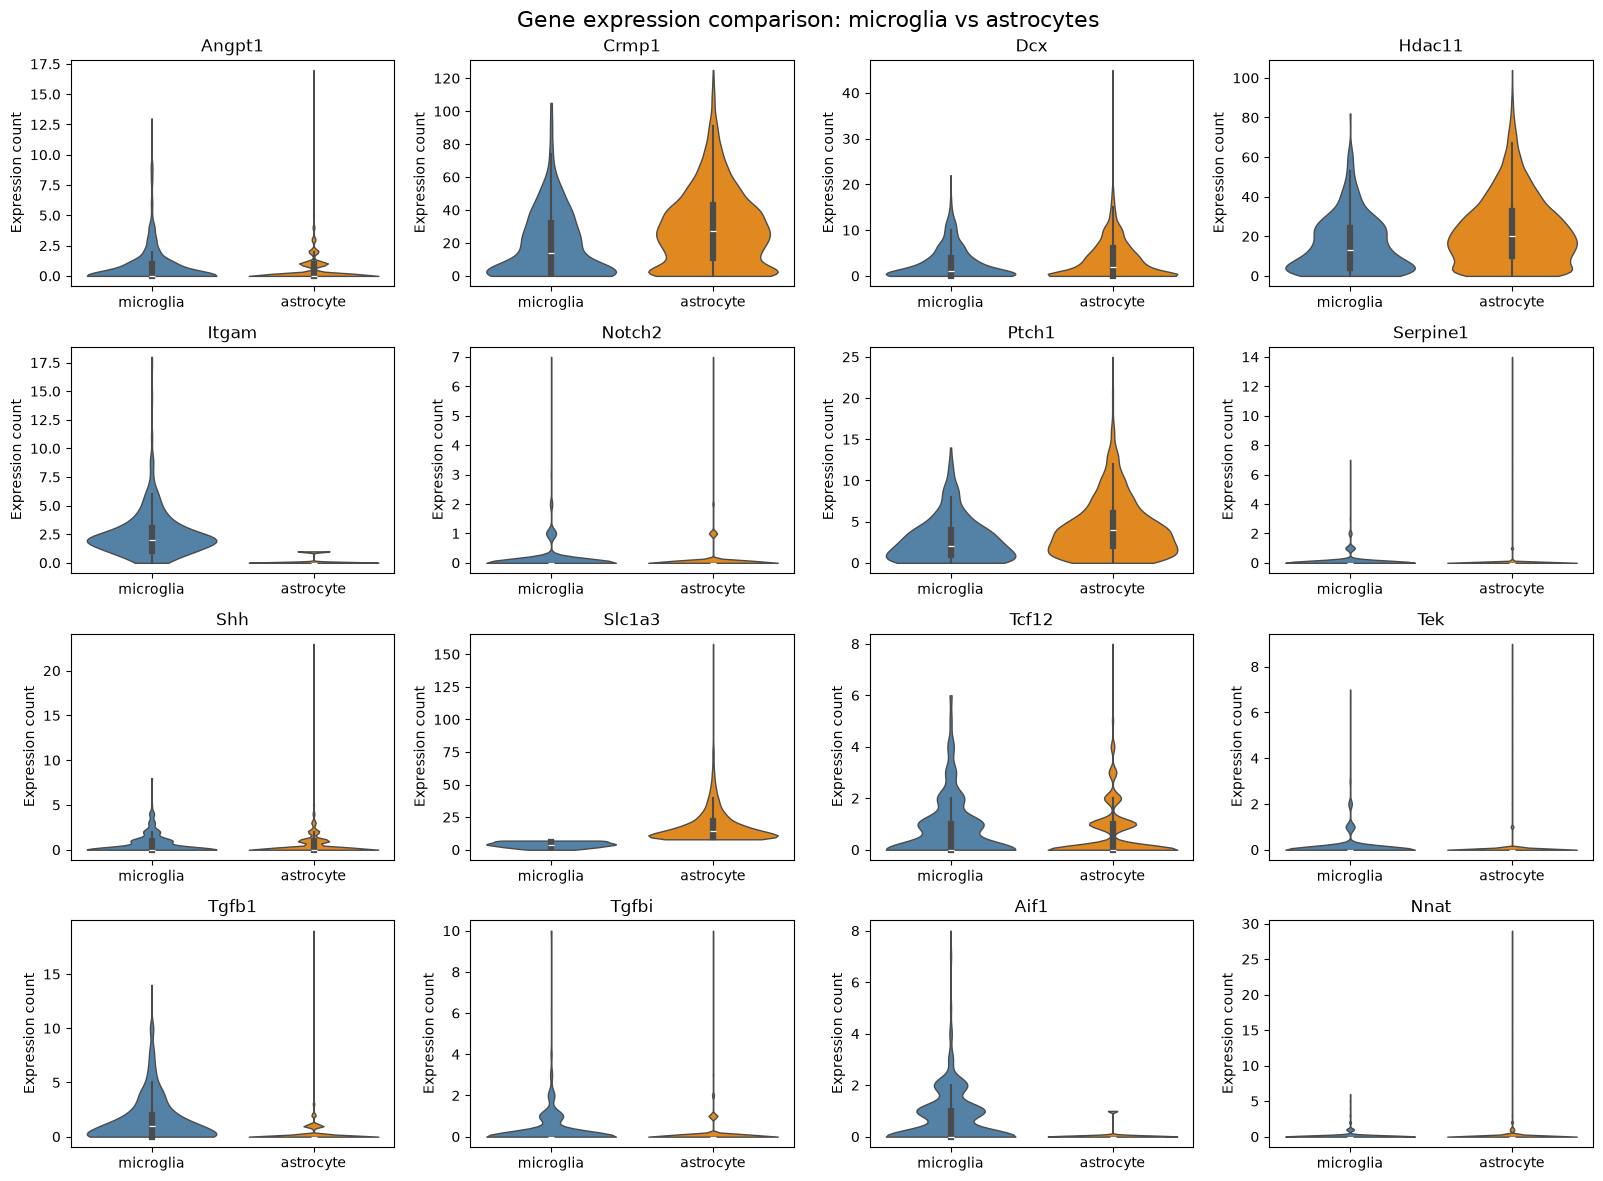

In [30]:
# Compare gene expression between microglia and astrocytes
comparison_labels = ["microglia", "astrocyte"]
plot_mask = cell_labels.isin(comparison_labels)

plot_data = counts.loc[plot_mask].copy()
plot_data["cell_type"] = cell_labels.loc[plot_mask].values

genes = counts.columns
fig, axes = plt.subplots(4, 4, figsize=(16, 12), sharey=False)
axes = axes.ravel()

for ax, gene in zip(axes, genes):
    sns.violinplot(
        data=plot_data,
        x="cell_type",
        y=gene,
        order=comparison_labels,
        inner="box",
        cut=0,
        linewidth=1,
        palette={"microglia": "steelblue", "astrocyte": "darkorange"},
        ax=ax,
    )
    ax.set_title(gene)
    ax.set_xlabel("")
    ax.set_ylabel("Expression count")

fig.suptitle("Gene expression comparison: microglia vs astrocytes", fontsize=16)
plt.tight_layout()
plt.show()

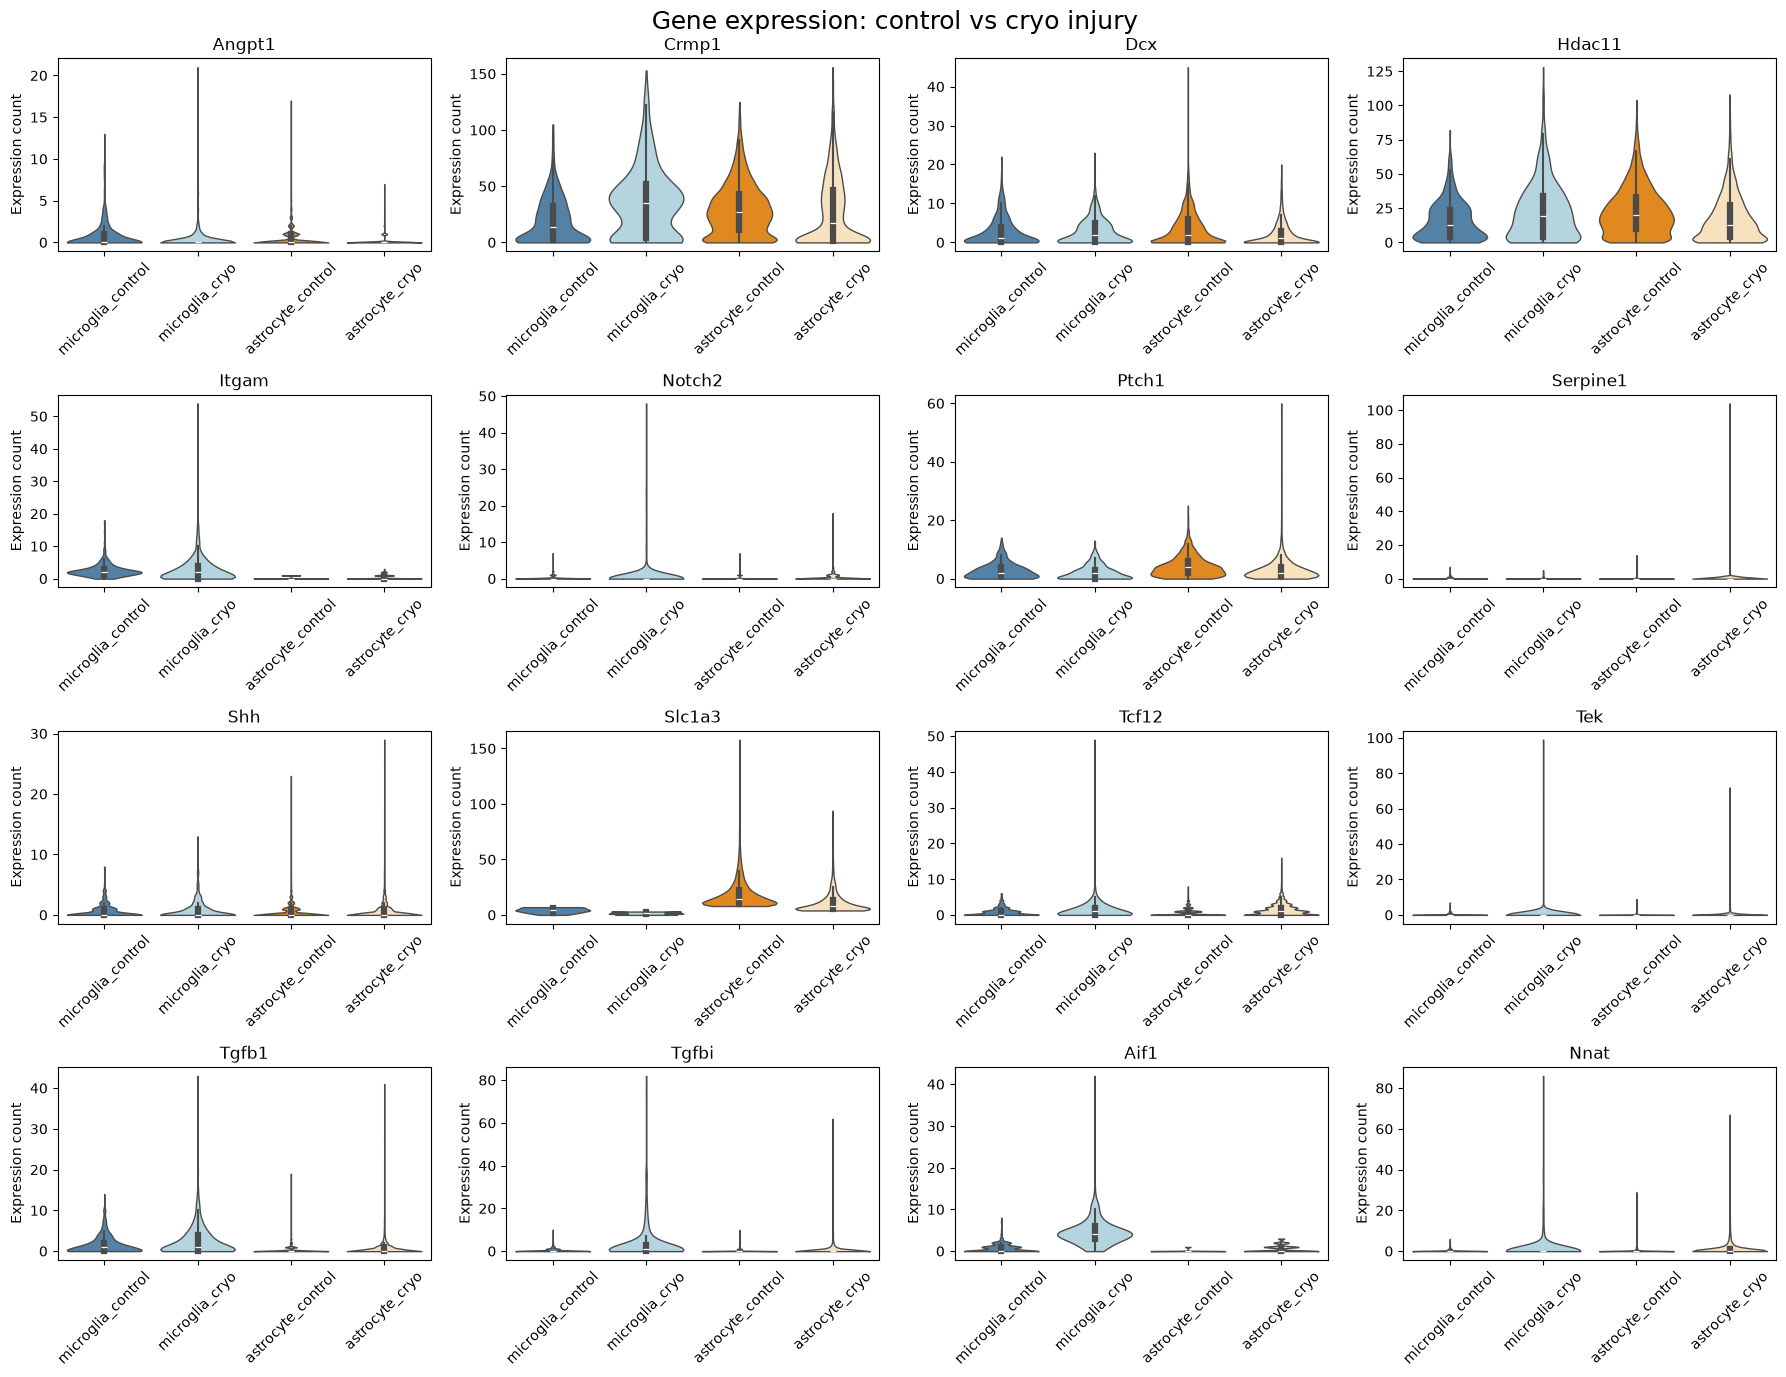

In [35]:
# Compare control and cryo expression for microglia and astrocytes
cell_types = ["microglia", "astrocyte"]
condition_order = [
    "microglia_control",
    "microglia_cryo",
    "astrocyte_control",
    "astrocyte_cryo",
]

control_data = counts.loc[cell_labels.isin(cell_types), genes].copy()
control_data["cell_type"] = cell_labels.loc[control_data.index]
control_data["condition"] = control_data["cell_type"] + "_control"

cryo_data = counts_cryo.loc[cryo_cell_labels.isin(cell_types), genes].copy()
cryo_data["cell_type"] = cryo_cell_labels.loc[cryo_data.index]
cryo_data["condition"] = cryo_data["cell_type"] + "_cryo"

comparison_data = pd.concat([control_data, cryo_data])
comparison_long = comparison_data.melt(
    id_vars=["cell_type", "condition"],
    value_vars=genes,
    var_name="gene",
    value_name="expression",
)

fig, axes = plt.subplots(4, 4, figsize=(18, 14), sharey=False)
axes = axes.ravel()

palette = {
    "microglia_control": "steelblue",
    "microglia_cryo": "lightblue",
    "astrocyte_control": "darkorange",
    "astrocyte_cryo": "moccasin",
}

for ax, gene in zip(axes, genes):
    gene_data = comparison_long[comparison_long["gene"] == gene]

    sns.violinplot(
        data=gene_data,
        x="condition",
        y="expression",
        order=condition_order,
        hue="condition",
        hue_order=condition_order,
        palette=palette,
        inner="box",
        cut=0,
        linewidth=1,
        legend=False,
        ax=ax,
    )

    ax.set_title(gene)
    ax.set_xlabel("")
    ax.set_ylabel("Expression count")
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Gene expression: control vs cryo injury", fontsize=18)
plt.tight_layout()
plt.show()